# Time-varying energy spectra for all Loon data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 2 # (minutes) the time step of the interpolated data

# Thresholds for limiting the size of spectra
PERIOD_MIN = 5 # (minutes) the minimum period to be included in the spectrum
PERIOD_MAX = 2*24*60 # (minutes) the maximum period to be included in the spectrum
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum GW period

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

# Instrumental uncertainties
GPS_uncertainty = 2.5 # (m) the Loon GPS uncertainty
u_uncertainty = np.sqrt(2)*GPS_uncertainty/30 # (m/s) the typical timestep in the raw data is 30s
v_uncertainty = np.sqrt(2)*GPS_uncertainty/30 # (m/s) the typical timestep in the raw data is 30s

### Load in the data

In [3]:
flights = pd.read_feather('5_flights_interptime_2daysegments_new_commontime.feather')
flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_cosmic,dTdz_cosmic,N_cosmic,altitude_spike,segment_id,segment_id_old
0,I-027,2013-04-19 21:10:00,38.560904,-113.923499,20586.130007,52.409555,5.868998,-3.926665,-60.174971,0.001718,49.000000,0.0,3,38
1,I-027,2013-04-19 21:12:00,38.556831,-113.915264,20611.196773,52.280057,5.787699,-3.533248,-60.131813,0.001728,49.000000,0.0,3,38
2,I-027,2013-04-19 21:14:00,38.553290,-113.907235,20581.595870,52.568178,5.646991,-3.188506,-60.182755,0.001716,49.000000,0.0,3,38
3,I-027,2013-04-19 21:16:00,38.550114,-113.899945,20606.535630,52.342452,5.485693,-3.143172,-60.142595,0.001726,49.000000,0.0,3,38
4,I-027,2013-04-19 21:18:00,38.546757,-113.892468,20581.674482,52.479827,5.664721,-3.223813,-60.096824,0.001688,48.000000,0.0,3,38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3909563,LN-324,2021-03-08 10:08:00,2.288987,71.312924,19432.212474,59.889808,-0.625520,-1.933254,-69.818583,0.005354,241.999087,0.0,124071,270099
3909564,LN-324,2021-03-08 10:10:00,2.287358,71.312195,19473.600113,59.497028,-0.825154,-1.688440,-69.611815,0.005228,240.328892,0.0,124071,270099
3909565,LN-324,2021-03-08 10:12:00,2.285122,71.311015,19479.659287,59.425407,-0.913618,-1.497904,-69.580083,0.005213,240.000000,0.0,124071,270099
3909566,LN-324,2021-03-08 10:14:00,2.283939,71.310120,19448.613840,59.703928,-0.836494,-1.310828,-69.743248,0.005290,240.000000,0.0,124071,270099


### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MAX):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the data have pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
    dTdz_env = np.array(segment.dTdz_cosmic)
    altitude_spike = np.array(segment.altitude_spike)
    
    # When N_cosmic = 0, set T_env and dTdz_env to np.nan
    # Later, when flight-mean rho_bar, H, Nref, and Z_EDS are calculated, use np.nanmean
    N_cosmic = np.array(segment.N_cosmic)
    T_env[N_cosmic == 0] = np.nan
    dTdz_env[N_cosmic == 0] = np.nan
    T_env = T_env[altitude_spike == 0]
    dTdz_env = dTdz_env[altitude_spike == 0]
    
    # Calculate segment mean density. Because Loon temperature data is unreliable, use the
    # environmental temperature from the COSMIC profiles
    temp_pt = pt[altitude_spike == 0]
    rho_bar = np.nanmean(temp_pt/(R*T_env))
    
    # Calculate the segment mean temperature and lapse rate
    T_env = np.nanmean(T_env)
    dTdz_env = np.nanmean(dTdz_env)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))    
    
    # Calculate the segment mean environmental buoyancy frequency and Z_EDS
    Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_spectra_output = segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                                             omega0,dt,dj,
                                             Nref,rho_bar,Omega,Z_EDS,PERIOD_MAX,GW_PERIOD_MAX)
    
    return segment_spectra_output

### Calculate energy spectra time series

In [6]:
def segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                    omega0,dt,dj,
                    Nref,rho_bar,Omega,Z_EDS,PERIOD_MAX,GW_PERIOD_MAX):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    
    
    
    ## ENERGY WAVELET
    # Calculate the EKE from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    # Calculate the EPE from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    # Calculate total energy
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    del wave_Ekh, wave_Ekv, wave_Ep
    
    
    
    ## PROCESS THE WAVELET
    # Remove zero padding
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete the offending wavelet coefficients
    wave_Etotal = wave_Etotal*temp1
    del temp1
    # Identify the periods less than or equal to PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= PERIOD_MAX]
    nscales_new = nscales_new.size
    period = period[:nscales_new]
    wave_Etotal = wave_Etotal[:nscales_new,:]
    # Identify the periods greater or equal to PERIOD_MIN
    ind = np.arange(nscales_new)
    ind = ind[period >= PERIOD_MIN]
    ind = ind[0]
    period = period[ind:]
    wave_Etotal = wave_Etotal[ind:,:]
    # Convert to a DataFrame for output
    column_names = np.round(period,2).astype(np.str)
    segment_spectra_output = pd.DataFrame(wave_Etotal.swapaxes(0,1), columns=column_names)
    
    
    
    return segment_spectra_output

In [8]:
# Calculate momentum flux time series for each data segment

segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()

segments_analyzed = pd.DataFrame(columns = flights.columns)

for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MAX)
    temp.index = segment.index
    segment = pd.concat([segment, temp], axis=1)
    segments_analyzed = segments_analyzed.append(segment, ignore_index=True)
    print('')

segments_analyzed.to_feather('Loon_omega0_8_EtotalWavelet_f_cutoff.feather')

Analyzing segment 1 out of 943 segments
Segment length: 3 days 00:04:00
Current time: 2025-07-30 15:30:34.733390

Analyzing segment 2 out of 943 segments
Segment length: 2 days 02:56:00
Current time: 2025-07-30 15:30:35.089115

Analyzing segment 3 out of 943 segments
Segment length: 4 days 18:10:00
Current time: 2025-07-30 15:30:35.227518

Analyzing segment 4 out of 943 segments
Segment length: 8 days 03:32:00
Current time: 2025-07-30 15:30:35.788001

Analyzing segment 5 out of 943 segments
Segment length: 2 days 19:00:00
Current time: 2025-07-30 15:30:36.852137

Analyzing segment 6 out of 943 segments
Segment length: 49 days 22:20:00
Current time: 2025-07-30 15:30:37.161827

Analyzing segment 7 out of 943 segments
Segment length: 5 days 06:02:00
Current time: 2025-07-30 15:30:46.887379

Analyzing segment 8 out of 943 segments
Segment length: 17 days 12:36:00
Current time: 2025-07-30 15:30:47.344379

Analyzing segment 9 out of 943 segments
Segment length: 5 days 20:06:00
Current time: 


Analyzing segment 73 out of 943 segments
Segment length: 3 days 15:34:00
Current time: 2025-07-30 15:32:46.893017

Analyzing segment 74 out of 943 segments
Segment length: 2 days 10:38:00
Current time: 2025-07-30 15:32:47.470709

Analyzing segment 75 out of 943 segments
Segment length: 3 days 00:00:00
Current time: 2025-07-30 15:32:47.926250

Analyzing segment 76 out of 943 segments
Segment length: 2 days 01:46:00
Current time: 2025-07-30 15:32:48.517752

Analyzing segment 77 out of 943 segments
Segment length: 5 days 04:08:00
Current time: 2025-07-30 15:32:49.001785

Analyzing segment 78 out of 943 segments
Segment length: 7 days 00:36:00
Current time: 2025-07-30 15:32:49.956329

Analyzing segment 79 out of 943 segments
Segment length: 2 days 19:04:00
Current time: 2025-07-30 15:32:51.185943

Analyzing segment 80 out of 943 segments
Segment length: 6 days 00:18:00
Current time: 2025-07-30 15:32:51.822128

Analyzing segment 81 out of 943 segments
Segment length: 6 days 00:38:00
Curren


Analyzing segment 144 out of 943 segments
Segment length: 2 days 17:34:00
Current time: 2025-07-30 15:33:35.090362

Analyzing segment 145 out of 943 segments
Segment length: 2 days 09:10:00
Current time: 2025-07-30 15:33:35.670581

Analyzing segment 146 out of 943 segments
Segment length: 2 days 13:12:00
Current time: 2025-07-30 15:33:36.224947

Analyzing segment 147 out of 943 segments
Segment length: 4 days 07:36:00
Current time: 2025-07-30 15:33:36.798335

Analyzing segment 148 out of 943 segments
Segment length: 2 days 17:18:00
Current time: 2025-07-30 15:33:37.762888

Analyzing segment 149 out of 943 segments
Segment length: 18 days 13:26:00
Current time: 2025-07-30 15:33:38.339770

Analyzing segment 150 out of 943 segments
Segment length: 2 days 11:56:00
Current time: 2025-07-30 15:33:41.635638

Analyzing segment 151 out of 943 segments
Segment length: 4 days 04:18:00
Current time: 2025-07-30 15:33:42.271253

Analyzing segment 152 out of 943 segments
Segment length: 2 days 13:18


Analyzing segment 215 out of 943 segments
Segment length: 9 days 03:06:00
Current time: 2025-07-30 15:34:38.848270

Analyzing segment 216 out of 943 segments
Segment length: 2 days 07:42:00
Current time: 2025-07-30 15:34:40.587862

Analyzing segment 217 out of 943 segments
Segment length: 2 days 09:58:00
Current time: 2025-07-30 15:34:41.276677

Analyzing segment 218 out of 943 segments
Segment length: 5 days 05:40:00
Current time: 2025-07-30 15:34:41.978943

Analyzing segment 219 out of 943 segments
Segment length: 2 days 08:46:00
Current time: 2025-07-30 15:34:43.190274

Analyzing segment 220 out of 943 segments
Segment length: 2 days 12:38:00
Current time: 2025-07-30 15:34:43.920703

Analyzing segment 221 out of 943 segments
Segment length: 27 days 16:32:00
Current time: 2025-07-30 15:34:44.621758

Analyzing segment 222 out of 943 segments
Segment length: 2 days 07:54:00
Current time: 2025-07-30 15:34:47.713806

Analyzing segment 223 out of 943 segments
Segment length: 4 days 04:28


Analyzing segment 286 out of 943 segments
Segment length: 2 days 18:18:00
Current time: 2025-07-30 15:36:02.390762

Analyzing segment 287 out of 943 segments
Segment length: 2 days 23:52:00
Current time: 2025-07-30 15:36:03.391561

Analyzing segment 288 out of 943 segments
Segment length: 4 days 22:36:00
Current time: 2025-07-30 15:36:04.447322

Analyzing segment 289 out of 943 segments
Segment length: 3 days 08:56:00
Current time: 2025-07-30 15:36:05.579844

Analyzing segment 290 out of 943 segments
Segment length: 53 days 09:46:00
Current time: 2025-07-30 15:36:06.674088

Analyzing segment 291 out of 943 segments
Segment length: 2 days 21:36:00
Current time: 2025-07-30 15:36:13.746939

Analyzing segment 292 out of 943 segments
Segment length: 2 days 07:36:00
Current time: 2025-07-30 15:36:14.807423

Analyzing segment 293 out of 943 segments
Segment length: 2 days 18:58:00
Current time: 2025-07-30 15:36:15.721780

Analyzing segment 294 out of 943 segments
Segment length: 3 days 08:52


Analyzing segment 357 out of 943 segments
Segment length: 11 days 19:06:00
Current time: 2025-07-30 15:37:41.846583

Analyzing segment 358 out of 943 segments
Segment length: 3 days 08:04:00
Current time: 2025-07-30 15:37:44.128089

Analyzing segment 359 out of 943 segments
Segment length: 5 days 13:00:00
Current time: 2025-07-30 15:37:45.323021

Analyzing segment 360 out of 943 segments
Segment length: 2 days 10:20:00
Current time: 2025-07-30 15:37:47.039344

Analyzing segment 361 out of 943 segments
Segment length: 4 days 21:54:00
Current time: 2025-07-30 15:37:48.257363

Analyzing segment 362 out of 943 segments
Segment length: 2 days 10:04:00
Current time: 2025-07-30 15:37:49.598442

Analyzing segment 363 out of 943 segments
Segment length: 2 days 09:08:00
Current time: 2025-07-30 15:37:50.852423

Analyzing segment 364 out of 943 segments
Segment length: 2 days 00:24:00
Current time: 2025-07-30 15:37:52.044276

Analyzing segment 365 out of 943 segments
Segment length: 5 days 05:42

... (4 outputs left out)


Analyzing segment 712 out of 943 segments
Segment length: 2 days 07:26:00
Current time: 2025-07-30 15:56:42.614414

Analyzing segment 713 out of 943 segments
Segment length: 2 days 04:42:00
Current time: 2025-07-30 15:56:48.094668

Analyzing segment 714 out of 943 segments
Segment length: 4 days 04:52:00
Current time: 2025-07-30 15:56:53.302331

Analyzing segment 715 out of 943 segments
Segment length: 2 days 16:12:00
Current time: 2025-07-30 15:56:58.927882

Analyzing segment 716 out of 943 segments
Segment length: 5 days 03:16:00
Current time: 2025-07-30 15:57:04.537232

Analyzing segment 717 out of 943 segments
Segment length: 5 days 03:30:00
Current time: 2025-07-30 15:57:10.010757

Analyzing segment 718 out of 943 segments
Segment length: 4 days 15:22:00
Current time: 2025-07-30 15:57:15.549195

Analyzing segment 719 out of 943 segments
Segment length: 5 days 12:40:00
Current time: 2025-07-30 15:57:21.750522

Analyzing segment 720 out of 943 segments
Segment length: 2 days 17:54:


Analyzing segment 783 out of 943 segments
Segment length: 5 days 20:02:00
Current time: 2025-07-30 16:04:04.545161

Analyzing segment 784 out of 943 segments
Segment length: 3 days 15:44:00
Current time: 2025-07-30 16:04:10.644816

Analyzing segment 785 out of 943 segments
Segment length: 2 days 05:02:00
Current time: 2025-07-30 16:04:16.856687

Analyzing segment 786 out of 943 segments
Segment length: 3 days 05:46:00
Current time: 2025-07-30 16:04:22.890081

Analyzing segment 787 out of 943 segments
Segment length: 10 days 17:42:00
Current time: 2025-07-30 16:04:28.742447

Analyzing segment 788 out of 943 segments
Segment length: 2 days 17:14:00
Current time: 2025-07-30 16:04:37.788305

Analyzing segment 789 out of 943 segments
Segment length: 2 days 00:00:00
Current time: 2025-07-30 16:04:47.563213

Analyzing segment 790 out of 943 segments
Segment length: 5 days 02:42:00
Current time: 2025-07-30 16:04:54.147033

Analyzing segment 791 out of 943 segments
Segment length: 4 days 08:52


Analyzing segment 854 out of 943 segments
Segment length: 2 days 07:06:00
Current time: 2025-07-30 16:16:24.417928

Analyzing segment 855 out of 943 segments
Segment length: 2 days 23:26:00
Current time: 2025-07-30 16:16:34.769861

Analyzing segment 856 out of 943 segments
Segment length: 4 days 10:08:00
Current time: 2025-07-30 16:16:44.765581

Analyzing segment 857 out of 943 segments
Segment length: 5 days 10:52:00
Current time: 2025-07-30 16:16:56.674299

Analyzing segment 858 out of 943 segments
Segment length: 5 days 01:32:00
Current time: 2025-07-30 16:17:08.805071

Analyzing segment 859 out of 943 segments
Segment length: 3 days 15:06:00
Current time: 2025-07-30 16:17:20.915928

Analyzing segment 860 out of 943 segments
Segment length: 2 days 15:20:00
Current time: 2025-07-30 16:17:31.066886

Analyzing segment 861 out of 943 segments
Segment length: 2 days 11:36:00
Current time: 2025-07-30 16:17:41.488531

Analyzing segment 862 out of 943 segments
Segment length: 5 days 19:46:


Analyzing segment 925 out of 943 segments
Segment length: 3 days 00:50:00
Current time: 2025-07-30 16:33:14.073140

Analyzing segment 926 out of 943 segments
Segment length: 7 days 21:58:00
Current time: 2025-07-30 16:33:31.009092

Analyzing segment 927 out of 943 segments
Segment length: 10 days 05:44:00
Current time: 2025-07-30 16:33:48.426967

Analyzing segment 928 out of 943 segments
Segment length: 2 days 01:50:00
Current time: 2025-07-30 16:34:07.302016

Analyzing segment 929 out of 943 segments
Segment length: 11 days 15:56:00
Current time: 2025-07-30 16:34:22.650420

Analyzing segment 930 out of 943 segments
Segment length: 5 days 19:14:00
Current time: 2025-07-30 16:34:41.226711

Analyzing segment 931 out of 943 segments
Segment length: 3 days 16:54:00
Current time: 2025-07-30 16:35:00.559071

Analyzing segment 932 out of 943 segments
Segment length: 9 days 00:04:00
Current time: 2025-07-30 16:35:20.229247

Analyzing segment 933 out of 943 segments
Segment length: 6 days 08:3

In [3]:
# Load in the analyzed data
#flights = pd.read_feather('Loon_omega0_8_EtotalWavelet.feather')
flights = pd.read_feather('Loon_omega0_8_EtotalWavelet_f_cutoff.feather')

# Retrieve the periods
period_column_start = 14
period_column_stop = 233
period_names = np.array(flights.columns[period_column_start:period_column_stop+1])
period = np.array(flights.columns[period_column_start:period_column_stop+1]).astype('float')
frequency = 1/period
n_periods = period.size
n_data = flights.shape[0]

In [4]:
# Mark depressurizations
# My approach, based on running a few depressurizations through a wavelet analysis, is to mark
# both the depressurization and the data within 2 hours (to the nearsest hour, rounding up) or the 
# width of the depressurization, whichever is bigger, on either side of it.
flights['depressurization'] = 0

# Tropical Pacific
# Segment 284 (Flight I-195)
flights.loc[(flights.flight_id == 'I-195') & 
        (flights.time >= np.datetime64('2014-07-09 07:00:00')) &
        (flights.time <= np.datetime64('2014-07-09 15:00:00')), 'depressurization'] = 1

# Segment 7969 (Flight I-488)
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-21 18:00:00')) &
        (flights.time <= np.datetime64('2015-05-22 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-23 04:00:00')) &
        (flights.time <= np.datetime64('2015-05-23 16:00:00')), 'depressurization'] = 1

# Segment 8041 (Flight I-490)
flights.loc[(flights.flight_id == 'I-490') & 
        (flights.time >= np.datetime64('2015-06-24 07:00:00')) &
        (flights.time <= np.datetime64('2015-06-24 13:00:00')), 'depressurization'] = 1



# Tropical Atlantic
# Segment 6506 (Flight I-436)
flights.loc[(flights.flight_id == 'I-436') & 
        (flights.time >= np.datetime64('2015-04-09 01:00:00')) &
        (flights.time <= np.datetime64('2015-04-09 10:00:00')), 'depressurization'] = 1

# Segment 8957 (Flight NR-215)
flights.loc[(flights.flight_id == 'NR-215') & 
        (flights.time >= np.datetime64('2016-02-19 00:00:00')) &
        (flights.time <= np.datetime64('2016-02-19 13:00:00')), 'depressurization'] = 1



# Indian Ocean
# Segment 58 (Flight L-002)
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-15 18:00:00')) &
        (flights.time <= np.datetime64('2014-02-16 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-20 04:00:00')) &
        (flights.time <= np.datetime64('2014-02-21 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-26 20:00:00')) &
        (flights.time <= np.datetime64('2014-02-27 01:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-28 10:00:00')) &
        (flights.time <= np.datetime64('2014-03-01 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-03-03 04:00:00')) &
        (flights.time <= np.datetime64('2014-03-04 06:00:00')), 'depressurization'] = 1

# Segment 5672 (Flight I-361)
flights.loc[(flights.flight_id == 'I-361') & 
        (flights.time >= np.datetime64('2015-01-26 09:00:00')) &
        (flights.time <= np.datetime64('2015-01-27 09:00:00')), 'depressurization'] = 1



# Extratropical Pacific
# Segment 5782 (Flight I-379)
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 02:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 09:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 18:00:00')), 'depressurization'] = 1



# Extratropical Atlantic
# Segment 41 (Flight I-126)
flights.loc[(flights.flight_id == 'I-126') & 
        (flights.time >= np.datetime64('2013-12-23 14:00:00')) &
        (flights.time <= np.datetime64('2013-12-24 03:00:00')), 'depressurization'] = 1



# Southern Ocean
# Segment 543 (Flight I-208)
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-07 23:00:00')) &
        (flights.time <= np.datetime64('2014-08-08 05:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-09 11:00:00')) &
        (flights.time <= np.datetime64('2014-08-10 00:00:00')), 'depressurization'] = 1

# Segment 1303 (Flight I-248)
flights.loc[(flights.flight_id == 'I-248') & 
        (flights.time >= np.datetime64('2014-07-31 22:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 04:00:00')), 'depressurization'] = 1

# Segment 1585 (Flight I-254)
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-07-31 11:00:00')) &
        (flights.time <= np.datetime64('2014-07-31 17:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-08-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 12:00:00')), 'depressurization'] = 1

# Segment 1985 (Flight I-263)
flights.loc[(flights.flight_id == 'I-263') & 
        (flights.time >= np.datetime64('2014-08-02 02:00:00')) &
        (flights.time <= np.datetime64('2014-08-02 21:00:00')), 'depressurization'] = 1

# Segment 2141 (Flight I-267)
flights.loc[(flights.flight_id == 'I-267') & 
        (flights.time >= np.datetime64('2014-09-18 12:00:00')) &
        (flights.time <= np.datetime64('2014-09-18 19:00:00')), 'depressurization'] = 1

# Segment 3559 (Flight I-292)
flights.loc[(flights.flight_id == 'I-292') & 
        (flights.time >= np.datetime64('2014-11-12 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-13 06:00:00')), 'depressurization'] = 1

# Segment 3816 (Flight I-295)
flights.loc[(flights.flight_id == 'I-295') & 
        (flights.time >= np.datetime64('2014-12-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-12-01 13:00:00')), 'depressurization'] = 1

# Segment 3990 (Flight I-296)
flights.loc[(flights.flight_id == 'I-296') & 
        (flights.time >= np.datetime64('2014-12-26 08:00:00')) &
        (flights.time <= np.datetime64('2014-12-26 14:00:00')), 'depressurization'] = 1

# Segment 4060 (Flight I-298)
flights.loc[(flights.flight_id == 'I-298') & 
        (flights.time >= np.datetime64('2014-07-30 03:00:00')) &
        (flights.time <= np.datetime64('2014-07-30 10:00:00')), 'depressurization'] = 1

# Segment 4623 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-02 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-02 19:00:00')), 'depressurization'] = 1

# Segment 4637 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-29 11:00:00')) &
        (flights.time <= np.datetime64('2014-11-29 19:00:00')), 'depressurization'] = 1

# Segment 5216 (Flight I-338)
flights.loc[(flights.flight_id == 'I-338') & 
        (flights.time >= np.datetime64('2014-08-24 04:00:00')) &
        (flights.time <= np.datetime64('2014-08-24 17:00:00')), 'depressurization'] = 1

# Segment 6884 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-01-25 22:00:00')) &
        (flights.time <= np.datetime64('2015-01-26 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-01 19:00:00')) &
        (flights.time <= np.datetime64('2015-02-02 10:00:00')), 'depressurization'] = 1

# Segment 6885 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-05 12:00:00')) &
        (flights.time <= np.datetime64('2015-02-06 09:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-06 15:00:00')) &
        (flights.time <= np.datetime64('2015-02-07 08:00:00')), 'depressurization'] = 1

# Segment 7020 (Flight M-054)
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-03-31 20:00:00')) &
        (flights.time <= np.datetime64('2015-04-01 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-04-02 14:00:00')) &
        (flights.time <= np.datetime64('2015-04-02 22:00:00')), 'depressurization'] = 1

In [5]:
# Save segment-mean length and factors for the GW vertical velocity and potential energy uncertainties
# The vertical velocity factor is calculated so that the power of w_uncertainty is weighted by segment length
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()
segments_N = np.nan*np.ones(n_segments)
segments_w_factor = np.nan*np.ones(n_segments)
segments_Ep_factor = np.nan*np.ones(n_segments)
segments_Nref = np.nan*np.ones(n_segments)
for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    segments_N[i] = segment.shape[0]
    pt = 100*np.array(segment.pressure) # the data have pressure units of hPa; convert to Pa
    T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
    dTdz_env = np.array(segment.dTdz_cosmic)
    altitude_spike = np.array(segment.altitude_spike)
    N_cosmic = np.array(segment.N_cosmic)
    T_env[N_cosmic == 0] = np.nan
    dTdz_env[N_cosmic == 0] = np.nan
    T_env = T_env[altitude_spike == 0]
    dTdz_env = dTdz_env[altitude_spike == 0]
    T_env = np.nanmean(T_env)
    dTdz_env = np.nanmean(dTdz_env)
    Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    segments_w_factor[i] = (1/Z_EDS)**2
    segments_Ep_factor[i] = (Nref/Z_EDS)**2
    segments_Nref[i] = Nref
temp = segments_w_factor/segments_w_factor # To deal with any segments with NaN COSMIC data
segments_w_factor = np.sqrt(np.nansum(segments_w_factor*segments_N)/np.nansum(temp*segments_N))
temp = segments_Ep_factor/segments_Ep_factor # To deal with any segments with NaN COSMIC data
segments_Ep_factor = np.nansum(segments_Ep_factor*segments_N)/np.nansum(temp*segments_N)

# Make a matrix of all the values, marking as NaN any data during a depressurization
energy = np.nan*np.ones(shape=(n_periods,n_data))
depressurization_factor = np.ones(n_data)
temp = np.array(flights.depressurization)
depressurization_factor[temp == 1] = np.nan
for i in np.arange(n_periods):
    energy[i,:] = depressurization_factor*np.array(flights[period_names[i]])

# Delete the flight data to save space
del flights # to save space

In [6]:
# Calculate the mean energy spectrum and find the upper and lower quantiles
quant_low1 = 0.01
quant_high1 = 0.99
quant_low2 = 0.1
quant_high2 = 0.9

energy_mean = np.nanmean(energy, axis=1)
energy_quant_low1 = np.nanquantile(energy, quant_low1, axis=1)
energy_quant_high1 = np.nanquantile(energy, quant_high1, axis=1)
energy_quant_low2 = np.nanquantile(energy, quant_low2, axis=1)
energy_quant_high2 = np.nanquantile(energy, quant_high2, axis=1)

In [7]:
# The spectrum of instrumental uncertainty
# This is done by scaling a power spectrum with the shape frequency**2 (amplitude
# a linear function of frequency) so that its total power equals the square of
# the instrumental uncertainty.
scaling_factor_velocity = (np.log2(np.exp(1))/dj)/np.sum(frequency**3)
scaling_factor_altitude = (np.log2(np.exp(1))/dj)/np.sum(frequency)
u_uncertainty_power = scaling_factor_velocity*(u_uncertainty*frequency)**2
v_uncertainty_power = scaling_factor_velocity*(v_uncertainty*frequency)**2
w_uncertainty = segments_w_factor*np.sqrt(2)*GPS_uncertainty/30
w_uncertainty_power = scaling_factor_velocity*(w_uncertainty*frequency)**2
delta_b_uncertainty_power = scaling_factor_altitude*np.ones(n_periods)*GPS_uncertainty**2

# Energy of the uncertainty
Ekh_uncertainty = 0.5*(u_uncertainty_power + v_uncertainty_power)
Ekv_uncertainty = 0.5*w_uncertainty_power
Ep_uncertainty = 0.5*segments_Ep_factor*delta_b_uncertainty_power
Etotal_uncertainty = Ekh_uncertainty + Ekv_uncertainty + Ep_uncertainty

# Effective momentum flux spectrum due to the uncertainty
rho_temp = 0.1 # (kg/m**3)
lat_temp = -70 # (degN)
Nref_temp = 0.02 # (rad/s)
f_temp = 2*Omega*np.sin(np.pi*lat_temp/180)
frequency_rad = 2*np.pi*frequency/60
factor = (frequency_rad**2 - f_temp**2)/(Nref_temp**2 - f_temp**2)
factor = factor*(Nref_temp**2 - frequency_rad**2)/(Nref_temp**2 - f_temp**2)
factor = np.sqrt(factor)
Etotal_uncertainty_rescaled = factor*Etotal_uncertainty

# Isolate the GW frequency range and integrate
Etotal_uncertainty_rescaled[period < GW_PERIOD_MIN] = np.nan
max_period = min(GW_PERIOD_MAX, 2*np.pi/(np.abs(f_temp)*60))
Etotal_uncertainty_rescaled[period > max_period] = np.nan
Etotal_uncertainty_rescaled = 1000*rho_temp*dj*np.log(2)*np.nansum(Etotal_uncertainty_rescaled/period)
print('Effective momentum flux due to instrumental uncertainty (mPa):', Etotal_uncertainty_rescaled)

Effective momentum flux due to instrumental uncertainty (mPa): 0.5799710405952911


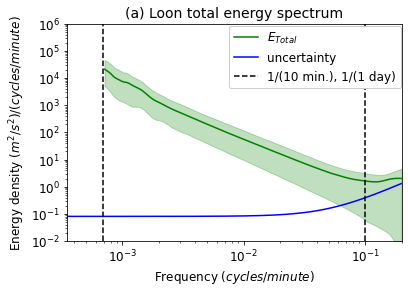

In [8]:
# Plot

ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(6,4))
plt.plot(frequency, energy_mean, 'g')
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2, color='g', alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'b')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([1/1440, 1/1440], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(a) Loon total energy spectrum', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'uncertainty',
            '1/(10 min.), 1/(1 day)'],
           loc='upper right', bbox_to_anchor=(1.016, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp6.pdf', format='pdf', bbox_inches='tight');

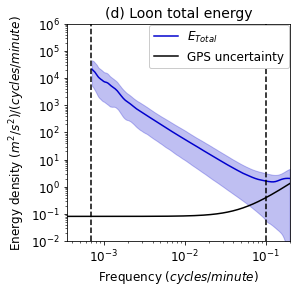

In [8]:
ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(4,4))
plt.plot(frequency, energy_mean, c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2,
                 color=matplotlib.colors.CSS4_COLORS['mediumblue'], alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'k')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([1/1440, 1/1440], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(d) Loon total energy', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'GPS uncertainty'],
           loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12);
plt.savefig('../plots/temp6a.pdf', format='pdf', bbox_inches='tight');